# 05 · LightGBM global forecaster
One model for *all* series (like the top M5 solutions), Tweedie objective because demand is non-negative,
zero-inflated count-like data.

In [1]:
import sys; sys.path.insert(0, "..")
import warnings, logging; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from src.config import *
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})

import lightgbm as lgb
from src.features import time_split
from src.metrics import wape, rmsse
feat = pd.read_parquet(PROC_DIR / "features.parquet")
FEATS = json.load(open(PROC_DIR / "feature_list.json"))
# categoricals were saved as category dtype in notebook 03 -> restore them
for c in ["item_id", "dept_id", "cat_id", "store_id", "state_id", "event_type_1"]:
    feat[c] = feat[c].astype("category")
tr, va, te = time_split(feat)

In [2]:
params = dict(objective="tweedie", tweedie_variance_power=1.3, learning_rate=0.05, num_leaves=63,
              min_data_in_leaf=50, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
              lambda_l2=1.0, verbose=-1, seed=SEED)
dtr = lgb.Dataset(tr[FEATS], tr.sales, categorical_feature=["item_id", "dept_id", "cat_id", "store_id", "state_id", "event_type_1"])
dva = lgb.Dataset(va[FEATS], va.sales, reference=dtr)
model = lgb.train(params, dtr, num_boost_round=1500, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])
print("best iteration:", model.best_iteration)

Training until validation scores don't improve for 50 rounds


[100]	valid_0's tweedie: 6.5804


[200]	valid_0's tweedie: 6.57956


Early stopping, best iteration is:
[174]	valid_0's tweedie: 6.5793
best iteration: 174


## Predict the test window and compare with the baselines

In [3]:
te = te.copy(); te["pred_lgbm"] = np.clip(model.predict(te[FEATS], num_iteration=model.best_iteration), 0, None)
hist = feat[feat.date < te.date.min()][["id", "date", "sales"]]
base = pd.read_parquet(OUT_DIR / "pred_baselines.parquet")
allp = te[["id", "date", "sales", "pred_lgbm"]].merge(base.drop(columns="sales"), on=["id", "date"])
allp.to_parquet(OUT_DIR / "pred_point.parquet")
res = pd.DataFrame([dict(model="lgbm", scope="all series", n_series=te.id.nunique(),
                         WAPE=wape(te.sales, te.pred_lgbm), RMSSE=rmsse(hist, te, "pred_lgbm"))])
top = base.dropna(subset=["pred_prophet"]).id.unique()
sub = allp[allp.id.isin(top)]
res = pd.concat([res, pd.DataFrame([dict(model="lgbm", scope=f"top {len(top)} series", n_series=len(top),
        WAPE=wape(sub.sales, sub.pred_lgbm), RMSSE=rmsse(hist[hist.id.isin(top)], sub, "pred_lgbm"))])]).round(4)
res.to_csv(OUT_DIR / "metrics_lgbm.csv", index=False)
pd.concat([pd.read_csv(OUT_DIR / "metrics_baselines.csv"), res]).sort_values(["scope", "WAPE"])

,model,n_series,WAPE,RMSSE,scope
0,lgbm,600,0.6699,0.8091,all series
2,ma28,600,0.7037,0.8428,all series
0,naive,600,0.8764,1.0720,all series
1,snaive,600,0.9299,1.1651,all series
0,lgbm,40,0.4834,0.8345,top 40 series
5,ma28,40,0.5171,0.8927,top 40 series
6,prophet,40,0.5264,0.8915,top 40 series
3,naive,40,0.6603,1.1249,top 40 series
4,snaive,40,0.7213,1.2373,top 40 series


## What drives the forecast?

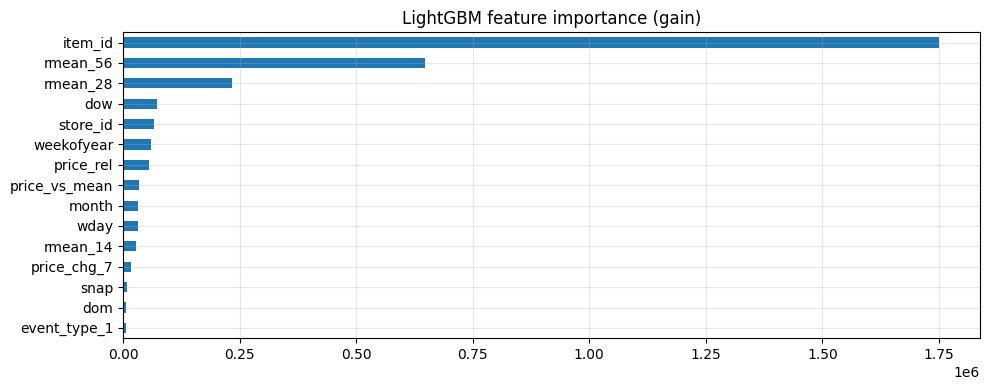

In [4]:
imp = pd.Series(model.feature_importance("gain"), index=FEATS).sort_values().tail(15)
imp.plot.barh(title="LightGBM feature importance (gain)"); plt.tight_layout()
plt.savefig(FIG_DIR / "05_importance.png", dpi=120); plt.show()
MODEL_DIR.mkdir(exist_ok=True); model.save_model(str(MODEL_DIR / "lgbm_global.txt"))

## Eyeball a few series

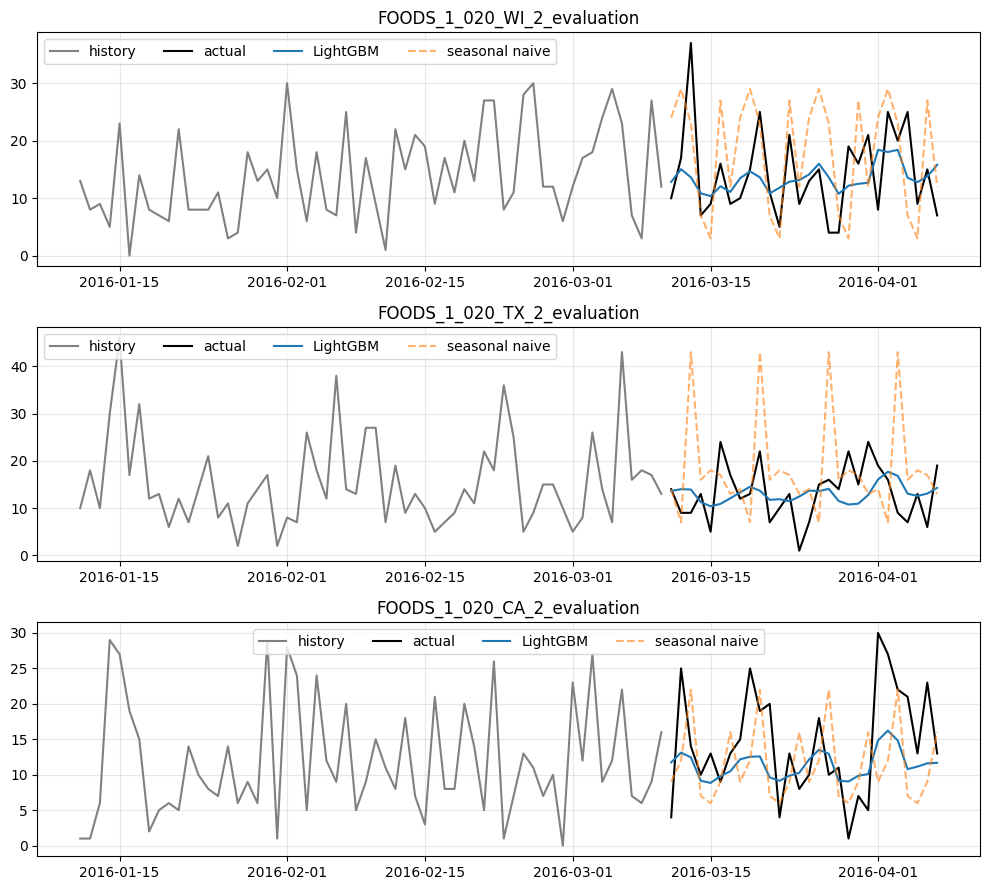

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9))
for ax, sid in zip(axes, hist.groupby("id")["sales"].sum().nlargest(3).index):
    h = hist[hist.id == sid].tail(60); t = allp[allp.id == sid].sort_values("date")
    ax.plot(h.date, h.sales, label="history", color="gray"); ax.plot(t.date, t.sales, label="actual", color="k")
    ax.plot(t.date, t.pred_lgbm, label="LightGBM"); ax.plot(t.date, t.pred_snaive, "--", label="seasonal naive", alpha=.6)
    ax.set_title(sid); ax.legend(ncol=4)
plt.tight_layout(); plt.savefig(FIG_DIR / "05_examples.png", dpi=120); plt.show()